# Exercise 1 - Linear Growth

The necessary functions are defined in the exercise_1.py file. 

**Differential equation:** $G_{NN} + (2 + d\ln H/dN)\,G_N - \tfrac{3}{2}\Omega_m(a)\,G = 0$,
with $G(a_i) = G_N(a_i) = a_i$.

**Normalization:** $D(a) = G(a)/G(1)$, so that $D(1) = 1$ and $f = G_N/G$.


In [55]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import quad
from pathlib import Path
from exercise_1 import E2, Om_a, dlnH_dN, growth_ode #Cosmological functions defined in the .py file

OUT = Path('output')
OUT.mkdir(exist_ok=True)

### Cosmological Models 

In [56]:
# (Om0 [Matter density], OL0 [Dark energy density]); Ok0 [Curvature density] = 1 - Om0 - OL0
models = {
    'EdS':       (1.0, 0.0),
    'flat LCDM': (0.3, 0.7),
    'open CDM':  (0.3, 0.0),
}

### a) Returning the growth factor and growth rate

In [57]:
ai = 1e-3 #Early in the matter-dominated regime

results = {}
for name, (Om0, OL0) in models.items():
    results[name] = growth_ode(Om0, OL0, ai=ai) #Testing for all cosmological models

# EdS: D = a and f = 1 exactly
a, D, f = results['EdS']
print('EdS: max|D - a| =', np.abs(D - a).max())
print('EdS: max|f - 1| =', np.abs(f - 1).max())

for name, (a, D, f) in results.items():
    print(f'{name:10s}  f(a=1) = {f[-1]:.4f}   D(ai)/ai = {D[0]/ai:.4f}')

EdS: max|D - a| = 1.1330081317595386e-10
EdS: max|f - 1| = 1.3322676295501878e-15
EdS         f(a=1) = 1.0000   D(ai)/ai = 1.0000
flat LCDM   f(a=1) = 0.5128   D(ai)/ai = 1.2837
open CDM    f(a=1) = 0.4917   D(ai)/ai = 2.1849


### b) Plotting the results for $D(a)$ and $f(a)$ for EdS, flat LCDM and Open CDM models

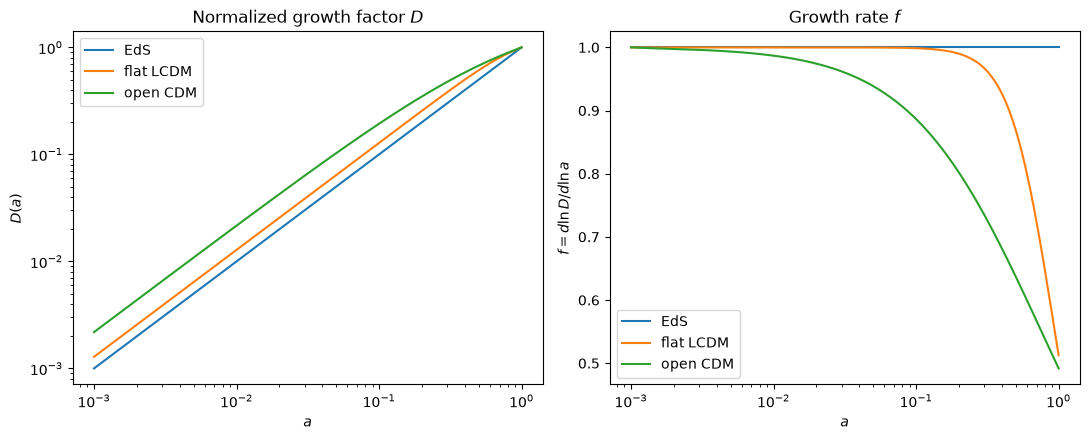

In [58]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for name, (a, D, f) in results.items():
    ax1.loglog(a, D, label=name)
    ax2.semilogx(a, f, label=name)

ax1.set_xlabel('$a$'); ax1.set_ylabel('$D(a)$')
ax1.set_title('Normalized growth factor $D$')
ax2.set_xlabel('$a$'); ax2.set_ylabel(r'$f = d\ln D/d\ln a$')
ax2.set_title('Growth rate $f$')
for ax in (ax1, ax2): ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'b_D_f.png', dpi=150)
plt.show()

EdS gives $D = a$ and $f = 1$ to scipy solver precision.
Since all curves are normalized to $D(1)=1$, LCDM and Open CDM lie above EdS at early times:
their growth is suppressed at late times ($G(1) < 1$), so $D = G/G(1) > a$ in the past.
The growth rate drops below 1 once $\Lambda$ or curvature become important:
$f(1) \approx 0.51$ (flat LCDM) and $\approx 0.49$ (Open CDM).


### c) Integral solution - quadrature

In [59]:
def growth_quad(Om0, OL0, a):
    E = lambda x: np.sqrt(E2(x, Om0, OL0)) #Hubble
    I = lambda x: quad(lambda t: 1 / (t**3 * E(t)**3), 0, x,
                       epsabs=0, epsrel=1e-12, limit=200)[0] #Integrand
    a = np.asarray(a)
    Ia = np.array([I(x) for x in a])
    G  = 2.5 * Om0 * E(a) * Ia
    G1 = 2.5 * Om0 * E(1.0) * I(1.0)
    f = dlnH_dN(a, Om0, OL0) + 1 / (a**2 * E(a)**3 * Ia)
    return G / G1, f

quad_results = {}
for name, (Om0, OL0) in models.items():
    a, D, f = results[name]
    quad_results[name] = growth_quad(Om0, OL0, a) 


### Plotting the difference between the methods

EdS         max|D/Dq-1| = 1.16e-09   max|f-fq| = 2.66e-15
flat LCDM   max|D/Dq-1| = 1.27e-09   max|f-fq| = 1.27e-09
open CDM    max|D/Dq-1| = 5.33e-04   max|f-fq| = 1.33e-03


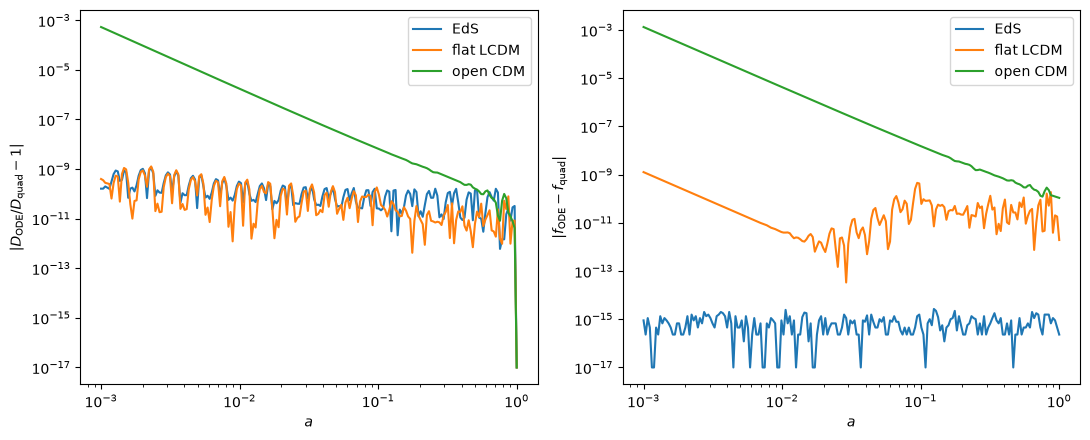

In [60]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for name in models:
    a, D, f = results[name]
    Dq, fq = quad_results[name]
    ax1.loglog(a, np.abs(D/Dq - 1) + 1e-17, label=name) #sum +1e-17 to avoid log(0)
    ax2.loglog(a, np.abs(f - fq) + 1e-17, label=name)
    print(f'{name:10s}  max|D/Dq-1| = {np.abs(D/Dq-1).max():.2e}   max|f-fq| = {np.abs(f-fq).max():.2e}')

ax1.set_ylabel(r'$|D_\mathrm{ODE}/D_\mathrm{quad} - 1|$')
ax2.set_ylabel(r'$|f_\mathrm{ODE} - f_\mathrm{quad}|$')
for ax in (ax1, ax2):
    ax.set_xlabel('$a$'); ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'c_ode_vs_quad.png', dpi=150)
plt.show()

EdS and flat LCDM agree to ~1e-9 (solver precision). Open CDM differs by ~5e-4 in D and ~1e-3 in f, largest at small a.

### d) Varying the initial scale factor $a_i$ and tolerances from the solvers

Note that the quadrature does not depend on $a_i$. We'll then use it as our reference (even though it also contains an integral tolerance).

### Changing $a_i$ and comparing the difference in each model

In [61]:
#Grid and reference
a_grid = np.geomspace(1e-2, 1, 100)
ref = {name: growth_quad(Om0, OL0, a_grid) for name, (Om0, OL0) in models.items()}

def errors(name, **kwargs):
    Om0, OL0 = models[name]
    _, D, f = growth_ode(Om0, OL0, a_eval=a_grid, **kwargs)
    Dq, fq = ref[name]
    return np.abs(D/Dq - 1).max(), np.abs(f - fq).max()

ai_values = [1e-2, 1e-3, 1e-4, 1e-5]
ai_scan = {name: [errors(name, ai=ai, rtol=1e-12, atol=1e-14) for ai in ai_values]
           for name in models}

for name, errs in ai_scan.items():
    for ai, (dD, df) in zip(ai_values, errs):
        print(f'{name:10s} ai={ai:.0e}   dD={dD:.2e}   df={df:.2e}')

EdS        ai=1e-02   dD=2.16e-12   df=2.11e-15
EdS        ai=1e-03   dD=2.32e-12   df=2.00e-15
EdS        ai=1e-04   dD=2.37e-12   df=2.33e-15
EdS        ai=1e-05   dD=2.17e-12   df=1.89e-15
flat LCDM  ai=1e-02   dD=5.09e-07   df=1.27e-06
flat LCDM  ai=1e-03   dD=3.44e-12   df=5.05e-12
flat LCDM  ai=1e-04   dD=2.49e-12   df=3.51e-12
flat LCDM  ai=1e-05   dD=3.30e-12   df=4.41e-12
open CDM   ai=1e-02   dD=5.26e-03   df=1.31e-02
open CDM   ai=1e-03   dD=1.72e-06   df=4.26e-06
open CDM   ai=1e-04   dD=5.44e-10   df=1.35e-09
open CDM   ai=1e-05   dD=3.59e-12   df=9.67e-12


### Changing the relative tolerance (rtol)

This parameter is the relative tolerance, such that each step is accepted only if its estimated error is below atol (absolute) + rtol·|y|, so rtol sets roughly how many significant digits of $G$ and $G_N$ are kept once $|y|$ is large compared with atol/rtol.

In [62]:
rtol_values = [1e-4, 1e-6, 1e-8, 1e-10, 1e-12]
rtol_scan = {name: [errors(name, ai=1e-5, rtol=rt, atol=rt*1e-5*1e-2) for rt in rtol_values]
             for name in models}

for name, errs in rtol_scan.items():
    for rt, (dD, df) in zip(rtol_values, errs):
        print(f'{name:10s} rtol={rt:.0e}   dD={dD:.2e}   df={df:.2e}')


EdS        rtol=1e-04   dD=1.66e-03   df=6.03e-13
EdS        rtol=1e-06   dD=4.11e-06   df=8.66e-15
EdS        rtol=1e-08   dD=2.12e-08   df=3.00e-15
EdS        rtol=1e-10   dD=1.60e-10   df=2.11e-15
EdS        rtol=1e-12   dD=1.44e-12   df=2.22e-15
flat LCDM  rtol=1e-04   dD=4.32e-04   df=3.06e-04
flat LCDM  rtol=1e-06   dD=3.19e-06   df=2.32e-06
flat LCDM  rtol=1e-08   dD=2.43e-08   df=5.58e-08
flat LCDM  rtol=1e-10   dD=1.64e-10   df=2.93e-10
flat LCDM  rtol=1e-12   dD=1.53e-12   df=3.46e-12
open CDM   rtol=1e-04   dD=2.61e-04   df=3.01e-04
open CDM   rtol=1e-06   dD=1.45e-06   df=1.89e-06
open CDM   rtol=1e-08   dD=1.59e-08   df=2.52e-08
open CDM   rtol=1e-10   dD=1.55e-10   df=4.26e-10
open CDM   rtol=1e-12   dD=1.96e-12   df=7.58e-12


### Plotting

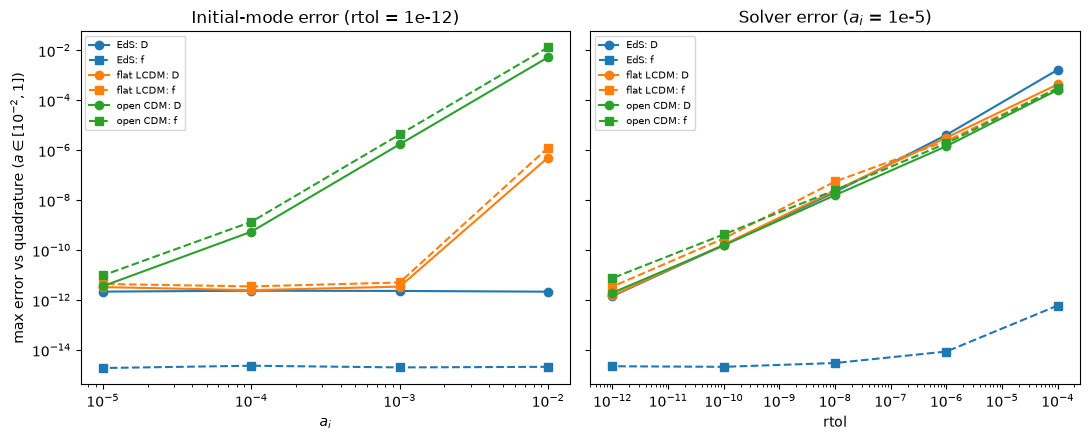

In [63]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for name in models:
    dD, df = np.array(ai_scan[name]).T
    l, = ax1.loglog(ai_values, dD + 1e-17, 'o-', label=f'{name}: D')
    ax1.loglog(ai_values, df + 1e-17, 's--', color=l.get_color(), label=f'{name}: f')
    dD, df = np.array(rtol_scan[name]).T
    l, = ax2.loglog(rtol_values, dD + 1e-17, 'o-', label=f'{name}: D')
    ax2.loglog(rtol_values, df + 1e-17, 's--', color=l.get_color(), label=f'{name}: f')

ax1.set_xlabel('$a_i$'); ax1.set_title('Initial-mode error (rtol = 1e-12)')
ax2.set_xlabel('rtol');  ax2.set_title('Solver error ($a_i$ = 1e-5)')
ax1.set_ylabel(r'max error vs quadrature ($a\in[10^{-2},1]$)')
for ax in (ax1, ax2): ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / 'd_convergence.png', dpi=150)
plt.show()

**Initial-mode error:** EdS is exact for any $a_i$, with dD ~ 2e-12. For LCDM the error is only visible
at $a_i = 10^{-2}$ and already at the floor for $a_i \le 10^{-3}$. Open CDM is much more sensitive, given that the curvature correction to the growing mode is of relative
order $a_i$, while Λ only enters at order $a_i^3$.

**Solver error:** At $a_i = 10^{-5}$ the error scales roughly linearly with `rtol`
in all three models, independently of the cosmology.
